<a href="https://colab.research.google.com/github/D-LukeSherman/ECGR-4105/blob/main/Homework5/Homework5_Problem1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import matplotlib.pyplot as plt

In [ ]:
# In[2]:
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

In [ ]:
# Standardize t_u: center mean at 0 and scale by standard deviation
t_u_mean = t_u.mean()
t_u_std = t_u.std()
t_un = (t_u - t_u_mean) / t_u_std

print('Mean of normalized t_un:', t_un.mean().item())
print('Std of normalized t_un:', t_un.std().item())

Mean of normalized t_un: -1.4088369937326206e-07
Std of normalized t_un: 1.0


In [ ]:
def model(t_u, w2, w1, b):
  return w2 * t_u ** 2 + w1 * t_u + b

In [ ]:
def loss_fn(t_p, t_c):
  squared_diffs = (t_p - t_c)**2
  return squared_diffs.mean()

In [ ]:
# In[5]:
w2 = torch.ones(())  # initial W is 1
w1 = torch.ones(())  # initial W is 1
b = torch.zeros(()) # initial b is 0
t_p = model(t_u, w2, w1, b)
t_p
# Out[5]:


tensor([1310.1901, 3180.7100, 3445.4399, 6789.5103, 3225.9900, 2440.1101,
        1183.1101,  497.0399, 2390.9600, 3708.5601, 4746.9600])

In [ ]:
# In[5]:
import torch.optim as optim
# dir(optim)

In [ ]:
# In[6]:
loss = loss_fn(t_p, t_c)
loss
# Out[6]:

tensor(11709471.)

In [ ]:
# In[8]:
params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
learning_rate = 1e-2
optimizer = optim.SGD([params], lr=learning_rate)

t_p = model(t_u, *params)
loss = loss_fn(t_p, t_c)

optimizer.zero_grad()
loss.backward()
optimizer.step()

params
# Out[8]:

tensor([-2.3149e+05, -3.6171e+03, -5.9642e+01], requires_grad=True)

In [ ]:
# In[9]:
def training_loop(n_epochs, learning_rate, params, t_u, t_c):
  loss_history = []
  for epoch in range(1, n_epochs + 1):
    if params.grad is not None:
      params.grad.zero_()

    t_p = model(t_u, *params)
    loss = loss_fn(t_p, t_c)
    loss.backward()

    with torch.no_grad():
      params -= learning_rate * params.grad

    if epoch == 1 or epoch % 500 == 0:
      # Calculate and store Root Mean Squared Error (RMSE) for tracking
      loss_history.append(loss.item())

  return params, loss_history

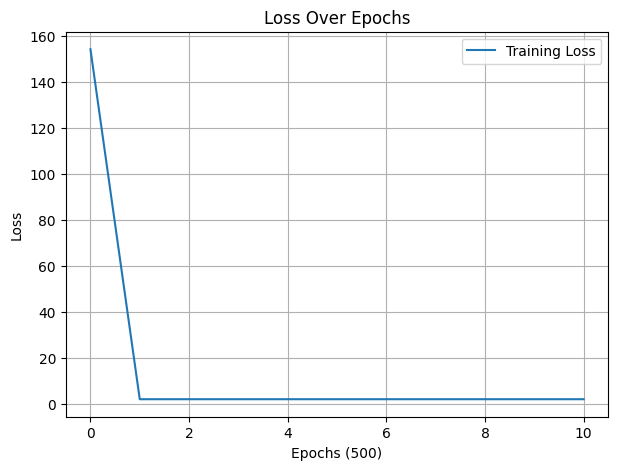

In [ ]:
# Train the model using the properly normalized inputs
# Since the inputs are normalized, we can use a stable learning rate such as 1e-2 or 1e-3
params, loss = training_loop(
  n_epochs = 5000,
  learning_rate = 1e-1,
  params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True),
  t_u = t_un,
  t_c = t_c
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(loss, label='Training Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss')
plt.title('Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
loss[10]

2.090719699859619

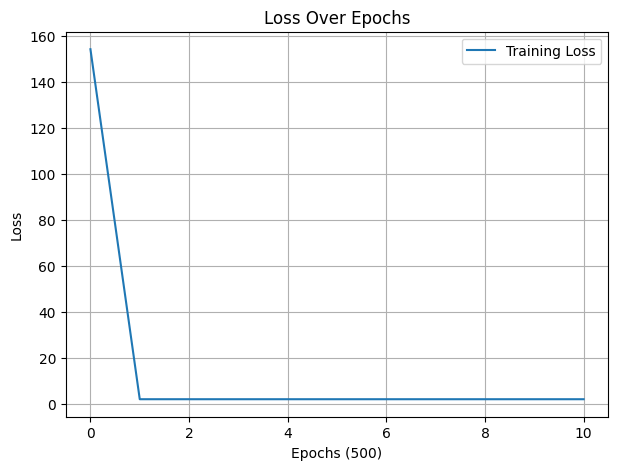

In [ ]:
# Train the model using the properly normalized inputs
# Since the inputs are normalized, we can use a stable learning rate such as 1e-2 or 1e-3
params, loss = training_loop(
  n_epochs = 5000,
  learning_rate = 1e-2,
  params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True),
  t_u = t_un,
  t_c = t_c
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(loss, label='Training Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss')
plt.title('Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

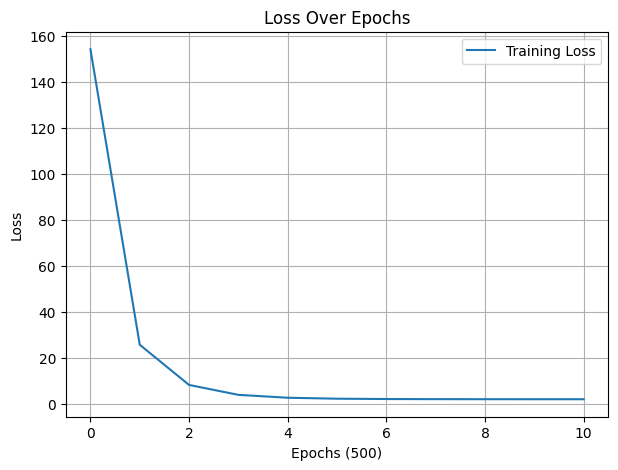

In [ ]:
# Train the model using the properly normalized inputs
# Since the inputs are normalized, we can use a stable learning rate such as 1e-2 or 1e-3
params, loss = training_loop(
  n_epochs = 5000,
  learning_rate = 1e-3,
  params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True),
  t_u = t_un,
  t_c = t_c
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(loss, label='Training Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss')
plt.title('Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

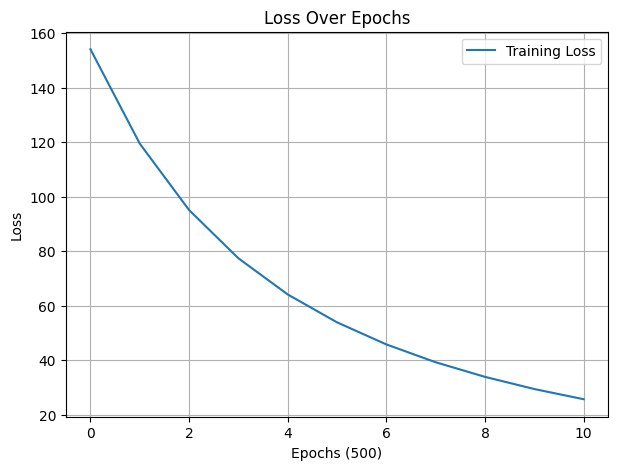

In [ ]:
# Train the model using the properly normalized inputs
# Since the inputs are normalized, we can use a stable learning rate such as 1e-2 or 1e-3
params, loss = training_loop(
  n_epochs = 5000,
  learning_rate = 1e-4,
  params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True),
  t_u = t_un,
  t_c = t_c
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(loss, label='Training Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss')
plt.title('Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()